# ECE 285 Homework 2: WikiArt GAN

This notebook trains a residual GAN on 64 x 64 WikiArt paintings. It caches resized images, trains with hinge loss and separate generator/discriminator learning rates, and evaluates an exponential moving average (EMA) of the generator with PyTorch-Ignite.

The image cache stays on Google Drive and is loaded into GPU memory for training. FID uses 2,048-dimensional Inception pool features; a separate probability-space FID is retained as a diagnostic.

In Colab, select a GPU runtime, review the configuration and Drive paths below, then run the cells in order. Existing run files are used to resume training. The submitted report and exported results accompany this notebook in the repository.


In [1]:
import subprocess
import sys

subprocess.run( [sys.executable, "-m", "pip", "install", "-q", "pytorch-ignite==0.5.5", "pypdf>=5,<7"], check=True, )


CompletedProcess(args=['/usr/bin/python3', '-m', 'pip', 'install', '-q', 'pytorch-ignite==0.5.5', 'pypdf>=5,<7'], returncode=0)

## 1. Imports


In [2]:
import copy
import csv
import hashlib
import json
import math
import os
import random
import shutil
import subprocess
import sys
import time
import urllib.request
from dataclasses import asdict, dataclass
from multiprocessing import Pool
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
from google.colab import drive, files
from ignite.metrics import FID, InceptionScore
from ignite.metrics.gan.fid import fid_score
from ignite.metrics.gan.utils import InceptionModel
from IPython.display import display
from PIL import Image
from pypdf import PdfReader
from torch.nn.utils import spectral_norm
from torchvision.datasets import ImageFolder
from torchvision.utils import make_grid, save_image
from tqdm.auto import tqdm

HAS_GPU = torch.cuda.is_available()
if not HAS_GPU:
    raise RuntimeError("No GPU detected. Select a T4 GPU under Runtime > Change runtime type, then rerun this cell.")
DEVICE = torch.device("cuda")
AMP = DEVICE.type == "cuda"          # Mixed precision (fp16).
POOL_DIM, PROB_DIM = 2048, 1000      # Inception pool features and class probabilities.

print("PyTorch:", torch.__version__, "| GPU:", torch.cuda.get_device_name(0))


PyTorch: 2.14.1+cu130 | GPU: Tesla T4


## 2. Configuration

Set `TRAIN_HOURS` to estimate the run length from a short speed benchmark, or set `EPOCHS` explicitly. A saved run configuration takes precedence when resuming. The recorded run used `ch=48` on a T4 GPU; changing the channel count creates a different model.


In [3]:
drive.mount("/content/drive")

# Student details for preparing a personal copy of the report.
STUDENT_NAME = "YOUR NAME"
STUDENT_PID = "YOUR PID"

# Training budget.
TRAIN_HOURS = 2.5   # Estimate the epoch count from a short speed benchmark.
EPOCHS = None       # Set an integer for a fixed run length; None uses TRAIN_HOURS.

# Dataset and output paths on Drive.
DRIVE_ZIP = Path("/content/drive/MyDrive/datasets/wikiart/wikiart.zip")
LOCAL_DATA_ROOT = Path("/content/wikiart")
# Use a separate run directory for each experiment.
DRIVE_RUN_DIR = Path("/content/drive/MyDrive/datasets/ECE285_HW2/wikiart_resgan64")


@dataclass(frozen=True)
class Config:
    image_size: int = 64
    latent_dim: int = 128
    ch: int = 48              # Base channel count; the recorded T4 run used 48.
    batch_size: int = 64
    lr_g: float = 1e-4        # The discriminator learning rate is four times larger.
    lr_d: float = 4e-4
    beta1: float = 0.0
    beta2: float = 0.9
    ema_decay: float = 0.999
    lr_decay_start: float = 0.5   # Start linear decay halfway through training.
    val_fraction: float = 0.10
    seed: int = 285
    eval_every: int = 5           # Epochs between FID monitoring passes.
    monitor_samples: int = 5000


CFG = Config()
DRIVE_RUN_DIR.mkdir(parents=True, exist_ok=True)
if STUDENT_NAME == "YOUR NAME" or STUDENT_PID == "YOUR PID":
    print("Set STUDENT_NAME and STUDENT_PID when preparing your own report.")
print(json.dumps(asdict(CFG), indent=2))


Mounted at /content/drive
{
  "image_size": 64,
  "latent_dim": 128,
  "ch": 48,
  "batch_size": 64,
  "lr_g": 0.0001,
  "lr_d": 0.0004,
  "beta1": 0.0,
  "beta2": 0.9,
  "ema_decay": 0.999,
  "lr_decay_start": 0.5,
  "val_fraction": 0.1,
  "seed": 285,
  "eval_every": 5,
  "monitor_samples": 5000
}


## 3. Cache the resized dataset

The first run extracts the archive, resizes each image, and saves a 64 x 64 uint8 cache to Drive. Later sessions can load that cache without decoding the original images again.


In [4]:
CACHE_NPY = DRIVE_RUN_DIR / "wikiart64_uint8.npy"
CACHE_META = DRIVE_RUN_DIR / "wikiart64_paths.json"
Image.MAX_IMAGE_PIXELS = None   # Allow the large source paintings in the WikiArt archive.


def locate_root(base):
    """Find a directory with at least 20 style subdirectories, allowing one wrapper level."""
    if not base.exists():
        return None
    for cand in [base] + [p for p in sorted(base.iterdir()) if p.is_dir()]:
        if sum(1 for p in cand.iterdir() if p.is_dir()) >= 20:
            return cand
    return None


def load_center_crop(path, size=CFG.image_size):
    """Resize the short side with bicubic sampling and center-crop; return None on failure."""
    try:
        with Image.open(path) as im:
            im.draft("RGB", (size * 2, size * 2))
            im = im.convert("RGB")
            w, h = im.size
            s = size / min(w, h)
            nw, nh = max(size, round(w * s)), max(size, round(h * s))
            im = im.resize((nw, nh), Image.BICUBIC)
            left, top = (nw - size) // 2, (nh - size) // 2
            return np.asarray(im.crop((left, top, left + size, top + size)), dtype=np.uint8)
    except Exception:
        return None


if CACHE_NPY.exists() and CACHE_META.exists():
    print("Found the 64 x 64 image cache; loading it directly.")
else:
    root = locate_root(LOCAL_DATA_ROOT)
    if root is None:
        zip_local = Path("/content/wikiart.zip")
        print("Copying and extracting wikiart.zip for the initial cache.")
        subprocess.run(["cp", str(DRIVE_ZIP), str(zip_local)], check=True)
        LOCAL_DATA_ROOT.mkdir(parents=True, exist_ok=True)
        subprocess.run(["unzip", "-o", "-q", str(zip_local), "-d", str(LOCAL_DATA_ROOT)], check=True)
        zip_local.unlink()
        root = locate_root(LOCAL_DATA_ROOT)
        assert root is not None, "No style directories found. Check the contents of wikiart.zip."

    samples = ImageFolder(str(root)).samples
    full_paths = [p for p, _ in samples]
    rel_all = [str(Path(p).relative_to(root)) for p in full_paths]
    arrays, kept, t0 = [], [], time.time()
    with Pool(os.cpu_count() or 2) as pool:
        stream = pool.imap(load_center_crop, full_paths, chunksize=32)
        for rel, arr in zip(rel_all, tqdm(stream, total=len(full_paths), desc="Resizing to 64x64")):
            if arr is None:
                print("Skipping unreadable image:", rel)
                continue
            arrays.append(arr)
            kept.append(rel)
    np.save(CACHE_NPY, np.stack(arrays))
    CACHE_META.write_text(json.dumps({"paths": kept, "image_size": CFG.image_size}))
    print(f"Cached {len(kept):,} images in {time.time() - t0:.0f}s at {CACHE_NPY}")


Found the 64 x 64 image cache; loading it directly.


## 4. Split the data and load it onto the GPU

A SHA-1 hash of each relative filename assigns approximately 10% of the images to the held-out split. Training uses random horizontal flips. A separate sample of training images provides the reference for FID monitoring.


classes=27 train=73,313 held-out=8,131 | GPU data 0.93 GiB


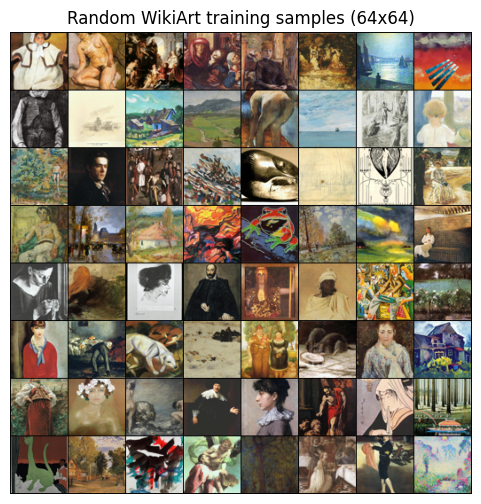

In [5]:
all_u8 = np.load(CACHE_NPY)                       # (N, 64, 64, 3) uint8
rel_paths = json.loads(CACHE_META.read_text())["paths"]
assert len(rel_paths) == len(all_u8)


def in_val(rel):
    """Assign held-out membership from the relative filename hash."""
    bucket = int.from_bytes(hashlib.sha1(rel.encode()).digest()[:4], "big") % 10_000
    return bucket < int(CFG.val_fraction * 10_000)


is_val = np.array([in_val(r) for r in rel_paths])
train_idx, val_idx = np.where(~is_val)[0], np.where(is_val)[0]
n_classes = len({r.split(os.sep)[0] for r in rel_paths})

rng = np.random.default_rng(CFG.seed)
ref_idx = rng.choice(train_idx, size=len(val_idx), replace=False)                         # Real-training versus held-out reference.
mon_idx = rng.choice(train_idx, size=min(CFG.monitor_samples, len(train_idx)), replace=False)  # Training reference for FID monitoring.

# Keep the uint8 image cache on the GPU to avoid repeated CPU decoding.
data_gpu = torch.from_numpy(all_u8).to(DEVICE)    # NHWC uint8
del all_u8
train_idx_t = torch.from_numpy(train_idx).to(DEVICE)
val_idx_t = torch.from_numpy(val_idx).to(DEVICE)
ref_idx_t = torch.from_numpy(ref_idx).to(DEVICE)
mon_idx_t = torch.from_numpy(mon_idx).to(DEVICE)
print(f"classes={n_classes} train={len(train_idx):,} held-out={len(val_idx):,} | GPU data {data_gpu.numel() / 2**30:.2f} GiB")


def u8_to_m11(x):   # uint8 NHWC -> float NCHW in [-1, 1].
    return x.permute(0, 3, 1, 2).float().div_(127.5).sub_(1.0)


def to_unit(x_m11, quantize=True):
    """Map [-1,1] to [0,1], optionally quantizing to the 8-bit grid used by the real images."""
    u = (x_m11.clamp(-1, 1) + 1) / 2
    return (u * 255).round() / 255 if quantize else u


def get_batch(idx):
    x = data_gpu[idx]                                              # (B, H, W, C)
    flip = torch.rand(x.shape[0], device=DEVICE) < 0.5            # Random horizontal flips.
    x = torch.where(flip[:, None, None, None], x.flip(2), x)
    return u8_to_m11(x)


preview = u8_to_m11(data_gpu[train_idx_t[torch.randperm(len(train_idx_t), device=DEVICE)[:64]]]).cpu()
plt.figure(figsize=(6, 6)); plt.axis("off"); plt.title("Random WikiArt training samples (64x64)")
plt.imshow(make_grid(preview, nrow=8, normalize=True, value_range=(-1, 1), padding=1).permute(1, 2, 0))
plt.show()


## 5. Generator and discriminator

The generator maps latent vectors through a linear layer and four residual upsampling blocks to a `tanh` output. The discriminator has five residual blocks and uses spectral normalization. Both networks are optimized with hinge loss.


In [6]:
def seed_everything(seed):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed); torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.benchmark = True


def conv(cin, cout, k, sn=False):
    layer = nn.Conv2d(cin, cout, k, 1, k // 2)
    nn.init.xavier_uniform_(layer.weight); nn.init.zeros_(layer.bias)
    return spectral_norm(layer) if sn else layer


class GBlock(nn.Module):
    """Residual upsampling block with BatchNorm and a 1x1 shortcut."""
    def __init__(self, cin, cout):
        super().__init__()
        self.bn1, self.c1 = nn.BatchNorm2d(cin), conv(cin, cout, 3)
        self.bn2, self.c2 = nn.BatchNorm2d(cout), conv(cout, cout, 3)
        self.sc = conv(cin, cout, 1)

    def forward(self, x):
        h = F.interpolate(F.relu(self.bn1(x)), scale_factor=2, mode="nearest")
        h = self.c2(F.relu(self.bn2(self.c1(h))))
        return h + F.interpolate(self.sc(x), scale_factor=2, mode="nearest")


class Generator(nn.Module):
    def __init__(self, nz=128, ch=48):
        super().__init__()
        w = [ch * 8, ch * 8, ch * 4, ch * 2, ch]          # 4x4 -> 8 -> 16 -> 32 -> 64
        self.w0 = w[0]
        self.fc = nn.Linear(nz, 4 * 4 * w[0])
        nn.init.xavier_uniform_(self.fc.weight); nn.init.zeros_(self.fc.bias)
        self.blocks = nn.Sequential(*[GBlock(w[i], w[i + 1]) for i in range(4)])
        self.out = nn.Sequential(nn.BatchNorm2d(w[-1]), nn.ReLU(True), conv(w[-1], 3, 3), nn.Tanh())

    def forward(self, z):
        h = self.fc(z.flatten(1)).view(-1, self.w0, 4, 4)
        return self.out(self.blocks(h))


class DBlock(nn.Module):
    """Residual discriminator block with spectral normalization on every convolution."""
    def __init__(self, cin, cout, first=False, down=True):
        super().__init__()
        self.c1, self.c2, self.sc = conv(cin, cout, 3, True), conv(cout, cout, 3, True), conv(cin, cout, 1, True)
        self.first, self.down = first, down

    def forward(self, x):
        h = x if self.first else F.relu(x)
        h = self.c2(F.relu(self.c1(h)))
        s = self.sc(x)
        if self.down:
            h, s = F.avg_pool2d(h, 2), F.avg_pool2d(s, 2)
        return h + s


class Discriminator(nn.Module):
    def __init__(self, ch=48):
        super().__init__()
        # 64 -> 32 -> 16 -> 8 -> 4 -> 4
        self.blocks = nn.Sequential( DBlock(3, ch, first=True), DBlock(ch, ch * 2), DBlock(ch * 2, ch * 4), DBlock(ch * 4, ch * 8), DBlock(ch * 8, ch * 8, down=False), )
        self.fc = spectral_norm(nn.Linear(ch * 8, 1))

    def forward(self, x):
        return self.fc(F.relu(self.blocks(x)).sum((2, 3))).flatten()


def make_models():
    G = Generator(CFG.latent_dim, CFG.ch).to(DEVICE).to(memory_format=torch.channels_last)
    D = Discriminator(CFG.ch).to(DEVICE).to(memory_format=torch.channels_last)
    return G, D


def make_opts(G, D):
    return ( torch.optim.Adam(G.parameters(), CFG.lr_g, betas=(CFG.beta1, CFG.beta2)), torch.optim.Adam(D.parameters(), CFG.lr_d, betas=(CFG.beta1, CFG.beta2)), )


def lr_scale(it, total):
    """Keep the initial rate for the first half, then decay linearly to a 2% floor."""
    start = CFG.lr_decay_start * total
    return 1.0 if it <= start else max(0.02, (total - it) / (total - start))


@torch.no_grad()
def update_ema(ema, model, it):
    decay = min(CFG.ema_decay, (1 + it) / (10 + it))       # Warm up EMA to reduce the influence of random initial weights.
    for pe, p in zip(ema.parameters(), model.parameters()):
        pe.lerp_(p, 1.0 - decay)


@torch.no_grad()
def recalibrate_bn(model, iters=40, bs=128):
    """Recompute BatchNorm running statistics for the EMA generator."""
    bns = [m for m in model.modules() if isinstance(m, nn.BatchNorm2d)]
    old = [m.momentum for m in bns]
    for m in bns:
        m.reset_running_stats(); m.momentum = None          # None uses a cumulative average.
    model.train()
    for _ in range(iters):
        with torch.autocast(DEVICE.type, dtype=torch.float16, enabled=AMP):
            model(torch.randn(bs, CFG.latent_dim, device=DEVICE))
    for m, mo in zip(bns, old):
        m.momentum = mo
    model.eval()


def sample_batches(G, n, bs=250, seed=None, amp=False):
    """Yield batches of float32 samples in [-1,1] to limit memory use."""
    gen = None
    if seed is not None:
        gen = torch.Generator(device=DEVICE); gen.manual_seed(seed)
    for i in range(0, n, bs):
        m = min(bs, n - i)
        with torch.no_grad(), torch.autocast(DEVICE.type, dtype=torch.float16, enabled=AMP and amp):
            x = G(torch.randn(m, CFG.latent_dim, device=DEVICE, generator=gen))
        yield x.float().clamp_(-1, 1)


def train_step(G, D, opt_g, opt_d, sc_g, sc_d, real):
    """Take one hinge-loss update for each network and return losses and mean discriminator scores."""
    z = torch.randn(real.shape[0], CFG.latent_dim, device=DEVICE)
    D.requires_grad_(True)
    with torch.autocast(DEVICE.type, dtype=torch.float16, enabled=AMP):
        fake = G(z)
        d_real, d_fake = D(real), D(fake.detach())
        loss_d = F.relu(1 - d_real.float()).mean() + F.relu(1 + d_fake.float()).mean()
    opt_d.zero_grad(set_to_none=True)
    sc_d.scale(loss_d).backward(); sc_d.step(opt_d); sc_d.update()

    D.requires_grad_(False)                                # Freeze discriminator parameters during the generator update.
    with torch.autocast(DEVICE.type, dtype=torch.float16, enabled=AMP):
        loss_g = -D(fake).float().mean()
    opt_g.zero_grad(set_to_none=True)
    sc_g.scale(loss_g).backward(); sc_g.step(opt_g); sc_g.update()
    D.requires_grad_(True)
    return loss_g.detach(), loss_d.detach(), d_real.detach().float().mean(), d_fake.detach().float().mean()


seed_everything(CFG.seed)
_G, _D = make_models()
n_params_g, n_params_d = sum(p.numel() for p in _G.parameters()), sum(p.numel() for p in _D.parameters())
print(f"G parameters: {n_params_g / 1e6:.2f}M | D parameters: {n_params_d / 1e6:.2f}M")
del _G, _D


G parameters: 5.00M | D parameters: 5.54M


## 6. Inception features and evaluation helpers


In [7]:
class InceptionExtractor(nn.Module):
    """
    Resize [0,1] images to 299x299 and apply ImageNet normalization.
    Return 2,048-dimensional pool features for FID or 1,000-class probabilities
    for Inception Score and the separate probability-space FID diagnostic.
    """
    def __init__(self, return_features):
        super().__init__()
        self.net = InceptionModel(return_features=return_features, device=DEVICE)
        self.register_buffer("mean", torch.tensor([0.485, 0.456, 0.406]).view(1, 3, 1, 1))
        self.register_buffer("std", torch.tensor([0.229, 0.224, 0.225]).view(1, 3, 1, 1))
        self.to(DEVICE)   # Move the normalization buffers to the GPU as well.

    @torch.no_grad()
    def forward(self, x01):
        x = F.interpolate(x01.float(), size=(299, 299), mode="bilinear", align_corners=False)
        return self.net((x - self.mean) / self.std)


def feats_to_stats(f):
    mu = f.mean(0)
    fc = f - mu
    return mu, fc.T @ fc / (f.shape[0] - 1)


@torch.no_grad()
def real_feats(extractor, idx_t, bs=250):
    outs = []
    for i in range(0, len(idx_t), bs):
        x = data_gpu[idx_t[i:i + bs]].permute(0, 3, 1, 2).float().div_(255)
        outs.append(extractor(x).double())
    return torch.cat(outs)


@torch.no_grad()
def fake_feats(extractor, G, n, seed=None, amp=False):
    return torch.cat([extractor(to_unit(x)).double() for x in sample_batches(G, n, 250, seed, amp)])


## 7. Train and save checkpoints

Each epoch saves a checkpoint and a fixed-noise sample grid to Drive. Every `eval_every` epochs, FID monitoring compares 5,000 generated images with the training reference sample and retains the best EMA generator. Final evaluation uses the held-out split in the next section.


In [8]:
CHECKPOINT_DIR, SAMPLE_DIR = DRIVE_RUN_DIR / "checkpoints", DRIVE_RUN_DIR / "samples"
CHECKPOINT_DIR.mkdir(parents=True, exist_ok=True); SAMPLE_DIR.mkdir(parents=True, exist_ok=True)
LATEST_PATH, BEST_PATH = CHECKPOINT_DIR / "latest.pt", CHECKPOINT_DIR / "best_ema.pt"
HISTORY_PATH, TRAINLOG_PATH, FIDLOG_PATH = DRIVE_RUN_DIR / "history.csv", DRIVE_RUN_DIR / "train_log.csv", DRIVE_RUN_DIR / "fid_log.csv"
RUN_CFG_PATH, MON_STATS_PATH = DRIVE_RUN_DIR / "run_config.json", DRIVE_RUN_DIR / "monitor_ref_stats.pt"

n_train = len(train_idx_t)
steps_per_epoch = n_train // CFG.batch_size


def append_rows(path, fields, rows):
    new = not path.exists()
    with path.open("a", newline="") as fh:
        w = csv.DictWriter(fh, fieldnames=fields)
        if new:
            w.writeheader()
        w.writerows(rows)


def benchmark_speed(n_warm=8, n_meas=24):
    """Measure seconds per iteration using temporary models."""
    G, D = make_models(); og, od = make_opts(G, D)
    sg, sd = torch.amp.GradScaler("cuda", enabled=AMP), torch.amp.GradScaler("cuda", enabled=AMP)
    for i in range(n_warm + n_meas):
        if i == n_warm:
            torch.cuda.synchronize(); t0 = time.perf_counter()
        idx = train_idx_t[torch.randint(0, n_train, (CFG.batch_size,), device=DEVICE)]
        train_step(G, D, og, od, sg, sd, get_batch(idx))
    torch.cuda.synchronize()
    return (time.perf_counter() - t0) / n_meas


# Choose the run length once and reuse it when resuming.
if RUN_CFG_PATH.exists():
    EPOCHS_FINAL = json.loads(RUN_CFG_PATH.read_text())["epochs"]
    print(f"Using the saved run length: {EPOCHS_FINAL} epochs. For a fresh run, use a new directory instead of {DRIVE_RUN_DIR.name}.")
else:
    if EPOCHS is None:
        sec_per_it = benchmark_speed()
        epoch_sec = sec_per_it * steps_per_epoch + 12          # Allow 12 seconds per epoch for sampling, saving, and monitoring.
        EPOCHS_FINAL = int(max(10, min(150, TRAIN_HOURS * 3600 * 0.92 // epoch_sec)))
        print(f"Measured {sec_per_it * 1000:.0f} ms/iter, about {epoch_sec:.0f} s/epoch; {TRAIN_HOURS}h budget -> {EPOCHS_FINAL} epochs")
    else:
        EPOCHS_FINAL = int(EPOCHS)
    RUN_CFG_PATH.write_text(json.dumps({ "epochs": EPOCHS_FINAL, "steps_per_epoch": steps_per_epoch, "config": asdict(CFG), "train_images": int(n_train), "heldout_images": int(len(val_idx_t)), "classes": n_classes, "params_g": n_params_g, "params_d": n_params_d, "gpu": torch.cuda.get_device_name(0), "torch": torch.__version__, }, indent=2))
TOTAL_ITERS = EPOCHS_FINAL * steps_per_epoch

# Initialize the models, optimizers, and EMA copy.
seed_everything(CFG.seed)
G, D = make_models(); opt_g, opt_d = make_opts(G, D)
scaler_g, scaler_d = torch.amp.GradScaler("cuda", enabled=AMP), torch.amp.GradScaler("cuda", enabled=AMP)
G_EMA = copy.deepcopy(G).eval().requires_grad_(False)
start_epoch, it, best_fid = 1, 0, float("inf")
if LATEST_PATH.exists():
    st = torch.load(LATEST_PATH, map_location=DEVICE, weights_only=False)
    G.load_state_dict(st["generator"]); D.load_state_dict(st["discriminator"]); G_EMA.load_state_dict(st["generator_ema"])
    opt_g.load_state_dict(st["optimizer_g"]); opt_d.load_state_dict(st["optimizer_d"])
    scaler_g.load_state_dict(st["scaler_g"]); scaler_d.load_state_dict(st["scaler_d"])
    start_epoch, it, best_fid = st["epoch"] + 1, st["iteration"], st["best_fid"]
    print(f"Resuming at epoch {start_epoch} (iteration {it})")

# Cache the real-image statistics used for FID monitoring.
EXT_POOL = InceptionExtractor(return_features=True)
if MON_STATS_PATH.exists():
    mon_mu, mon_sigma = [t.to(DEVICE) for t in torch.load(MON_STATS_PATH, map_location="cpu")]
else:
    mon_mu, mon_sigma = feats_to_stats(real_feats(EXT_POOL, mon_idx_t))
    torch.save([mon_mu.cpu(), mon_sigma.cpu()], MON_STATS_PATH)


def monitor_fid(g_ema):
    recalibrate_bn(g_ema)
    mu, sigma = feats_to_stats(fake_feats(EXT_POOL, g_ema, CFG.monitor_samples, amp=True))
    return float(fid_score(mu, mon_mu, sigma, mon_sigma))


fixed_z = torch.randn(64, CFG.latent_dim, generator=torch.Generator().manual_seed(CFG.seed)).to(DEVICE)

# Training loop.
print(f"Training {EPOCHS_FINAL} epochs x {steps_per_epoch} iters = {TOTAL_ITERS:,} iterations (batch {CFG.batch_size})")
LOG_WINDOW = 100
for epoch in range(start_epoch, EPOCHS_FINAL + 1):
    G.train(); D.train()
    began = time.perf_counter()
    perm = train_idx_t[torch.randperm(n_train, device=DEVICE)]
    acc, win, ep_acc, windows = torch.zeros(4, device=DEVICE), 0, torch.zeros(4, device=DEVICE), []
    bar = tqdm(range(steps_per_epoch), desc=f"Epoch {epoch}/{EPOCHS_FINAL}", leave=False, mininterval=5)
    for step in bar:
        it += 1
        s = lr_scale(it, TOTAL_ITERS)
        for g in opt_g.param_groups: g["lr"] = CFG.lr_g * s
        for g in opt_d.param_groups: g["lr"] = CFG.lr_d * s
        real = get_batch(perm[step * CFG.batch_size:(step + 1) * CFG.batch_size])
        vals = torch.stack(train_step(G, D, opt_g, opt_d, scaler_g, scaler_d, real))
        update_ema(G_EMA, G, it)
        acc += vals; ep_acc += vals; win += 1
        if win == LOG_WINDOW or step == steps_per_epoch - 1:
            m = (acc / win).tolist()
            windows.append(dict(iteration=it, g_loss=m[0], d_loss=m[1], d_real=m[2], d_fake=m[3]))
            bar.set_postfix(G=f"{m[0]:.2f}", D=f"{m[1]:.2f}", Dr=f"{m[2]:.2f}", Df=f"{m[3]:.2f}")
            acc.zero_(); win = 0
    train_seconds = time.perf_counter() - began
    em = (ep_acc / steps_per_epoch).tolist()

    # Use fixed noise to compare EMA samples across epochs.
    recalibrate_bn(G_EMA, iters=30)
    with torch.no_grad():
        grid = G_EMA(fixed_z).float()
    save_image(grid, SAMPLE_DIR / f"epoch_{epoch:04d}.png", nrow=8, normalize=True, value_range=(-1, 1), padding=1)

    fid_val = None
    if epoch % CFG.eval_every == 0 or epoch == EPOCHS_FINAL:
        try:
            fid_val = monitor_fid(G_EMA)
            append_rows(FIDLOG_PATH, ["epoch", "iteration", "fid"], [dict(epoch=epoch, iteration=it, fid=fid_val)])
            if fid_val < best_fid:
                best_fid = fid_val
                torch.save({"epoch": epoch, "iteration": it, "fid": fid_val, "generator_ema": G_EMA.state_dict()}, BEST_PATH)
        except Exception as e:                              # Continue training if a monitoring pass fails.
            print("FID monitoring failed; skipping this pass:", repr(e))

    append_rows(TRAINLOG_PATH, ["iteration", "g_loss", "d_loss", "d_real", "d_fake"], windows)
    append_rows(HISTORY_PATH, ["epoch", "iteration", "g_loss", "d_loss", "d_real", "d_fake", "lr_scale", "seconds"], [dict( epoch=epoch, iteration=it, g_loss=em[0], d_loss=em[1], d_real=em[2], d_fake=em[3], lr_scale=s, seconds=time.perf_counter() - began)])
    state = {"epoch": epoch, "iteration": it, "best_fid": best_fid, "config": asdict(CFG),
             "generator": G.state_dict(), "discriminator": D.state_dict(), "generator_ema": G_EMA.state_dict(),
             "optimizer_g": opt_g.state_dict(), "optimizer_d": opt_d.state_dict(),
             "scaler_g": scaler_g.state_dict(), "scaler_d": scaler_d.state_dict()}
    torch.save(state, CHECKPOINT_DIR / "latest.tmp"); os.replace(CHECKPOINT_DIR / "latest.tmp", LATEST_PATH)
    print(f"epoch {epoch:3d} | G {em[0]:.3f} D {em[1]:.3f} D(x) {em[2]:+.2f} D(G(z)) {em[3]:+.2f} | " f"{train_seconds:.0f}s" + (f" | FID-monitor {fid_val:.2f} (best {best_fid:.2f})" if fid_val is not None else ""))

print("Training complete. Best monitor FID =", best_fid)


Using the saved run length: 52 epochs. For a fresh run, use a new directory instead of wikiart_resgan64.
Resuming at epoch 53 (iteration 59540)
Downloading: "https://download.pytorch.org/models/inception_v3_google-0cc3c7bd.pth" to /root/.cache/torch/hub/checkpoints/inception_v3_google-0cc3c7bd.pth


100%|██████████| 104M/104M [00:00<00:00, 144MB/s] 


Training 52 epochs x 1145 iters = 59,540 iterations (batch 64)
Training complete. Best monitor FID = 29.111679490257814


## 8. Final FID and Inception Score


Using the EMA generator from epoch 50 (best_ema.pt)


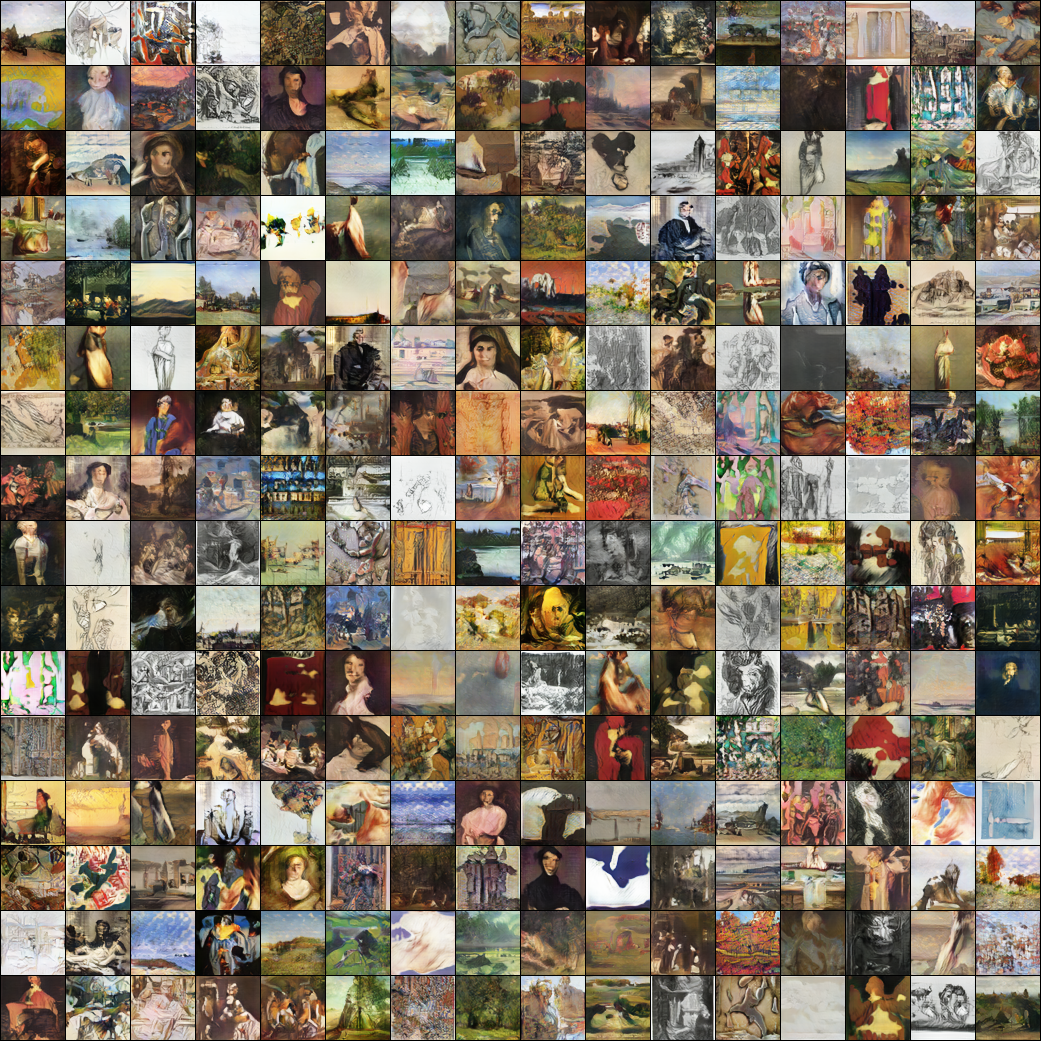

{
  "fid": 25.047675802811284,
  "inception_score": 5.134609074900177,
  "fid_ignite_default_softmax_features": 0.03536984567924478,
  "reference_fid_real_train_vs_heldout": 7.186132991343072,
  "reference_is_real_heldout": 7.485934313650706,
  "num_generated": 8131,
  "num_real_heldout": 8131,
  "checkpoint_epoch": 50,
  "epochs_trained": 52,
  "seed": 285,
  "image_size": 64,
  "ema_generator": true
}


In [9]:
# Load the best monitored EMA generator and recalibrate BatchNorm.
ckpt_path = BEST_PATH if BEST_PATH.exists() else LATEST_PATH
ck = torch.load(ckpt_path, map_location=DEVICE, weights_only=False)
G_final = Generator(CFG.latent_dim, CFG.ch).to(DEVICE).to(memory_format=torch.channels_last)
G_final.load_state_dict(ck["generator_ema"]); G_final.requires_grad_(False)
recalibrate_bn(G_final, iters=100, bs=250)
print(f"Using the EMA generator from epoch {ck['epoch']} ({ckpt_path.name})")

FINAL_SAMPLES_PATH = DRIVE_RUN_DIR / "final_samples.png"
save_image(next(sample_batches(G_final, 256, 256, seed=CFG.seed)), FINAL_SAMPLES_PATH, nrow=16, normalize=True, value_range=(-1, 1), padding=1)
display(Image.open(FINAL_SAMPLES_PATH))

# Final evaluation with PyTorch-Ignite.
# Use 2,048-dimensional pool features for the reported FID.
# Keep the 1,000-dimensional probability-space result as a separate diagnostic.
N_EVAL = len(val_idx_t)
EXT_PROB = InceptionExtractor(return_features=False)
fid_metric = FID(num_features=POOL_DIM, feature_extractor=EXT_POOL, device=DEVICE)      # Reported pool-feature FID.
fid_default = FID(num_features=PROB_DIM, feature_extractor=EXT_PROB, device=DEVICE)     # Probability-space diagnostic.
is_metric = InceptionScore(num_features=PROB_DIM, feature_extractor=EXT_PROB, device=DEVICE)
fid_ref = FID(num_features=POOL_DIM, feature_extractor=EXT_POOL, device=DEVICE)         # Real-training versus held-out reference.
is_real = InceptionScore(num_features=PROB_DIM, feature_extractor=EXT_PROB, device=DEVICE)

gen = torch.Generator(device=DEVICE); gen.manual_seed(CFG.seed + 1)
for i in tqdm(range(0, N_EVAL, 250), desc="FID / IS"):
    m = min(250, N_EVAL - i)
    with torch.no_grad():
        fake = to_unit(G_final(torch.randn(m, CFG.latent_dim, device=DEVICE, generator=gen)).float())
    real = data_gpu[val_idx_t[i:i + m]].permute(0, 3, 1, 2).float().div_(255)
    ref = data_gpu[ref_idx_t[i:i + m]].permute(0, 3, 1, 2).float().div_(255)
    fid_metric.update((fake, real)); fid_default.update((fake, real)); is_metric.update(fake)
    fid_ref.update((ref, real)); is_real.update(real)

run_cfg = json.loads(RUN_CFG_PATH.read_text())
metrics = {
    "fid": float(fid_metric.compute()),
    "inception_score": float(is_metric.compute()),
    "fid_ignite_default_softmax_features": float(fid_default.compute()),
    "reference_fid_real_train_vs_heldout": float(fid_ref.compute()),
    "reference_is_real_heldout": float(is_real.compute()),
    "num_generated": N_EVAL, "num_real_heldout": N_EVAL,
    "checkpoint_epoch": int(ck["epoch"]), "epochs_trained": run_cfg["epochs"],
    "seed": CFG.seed, "image_size": CFG.image_size, "ema_generator": True,
}
METRICS_PATH = DRIVE_RUN_DIR / "metrics.json"
METRICS_PATH.write_text(json.dumps(metrics, indent=2))
print(json.dumps(metrics, indent=2))


## 9. Figures for the report


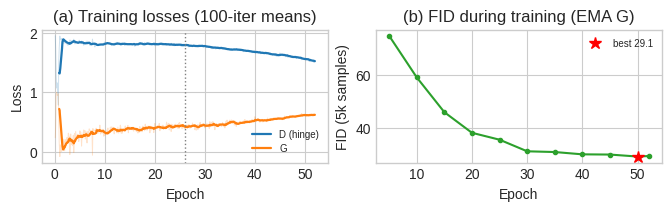

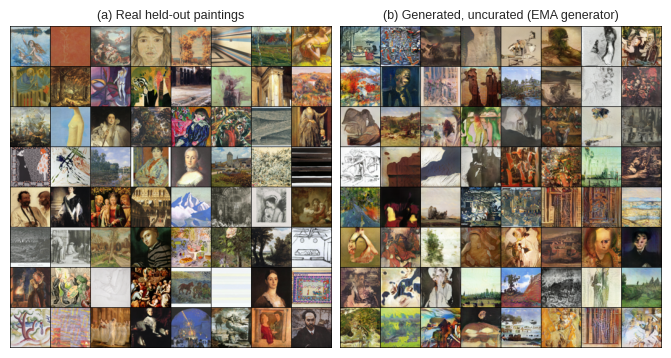

In [10]:
def read_csv(path):
    if not path.exists():
        return None
    rows = list(csv.DictReader(path.open()))
    return {k: np.array([float(r[k]) for r in rows]) for k in rows[0]} if rows else None


tl, hist, fl = read_csv(TRAINLOG_PATH), read_csv(HISTORY_PATH), read_csv(FIDLOG_PATH)


def smooth(y, k):
    k = max(1, min(k, len(y)))
    return np.convolve(y, np.ones(k) / k, mode="valid"), k


plt.style.use("seaborn-v0_8-whitegrid")
fig, ax = plt.subplots(1, 2, figsize=(6.6, 2.0), constrained_layout=True)
x = tl["iteration"] / steps_per_epoch
for label, key, color in [("D (hinge)", "d_loss", "C0"), ("G", "g_loss", "C1")]:
    ys, k = smooth(tl[key], 10)
    ax[0].plot(x, tl[key], color=color, alpha=0.22, lw=0.7)
    ax[0].plot(x[k - 1:], ys, color=color, lw=1.6, label=label)
ax[0].axvline(CFG.lr_decay_start * run_cfg["epochs"], color="gray", ls=":", lw=1)
ax[0].set(xlabel="Epoch", ylabel="Loss", title="(a) Training losses (100-iter means)"); ax[0].legend(fontsize=7)
if fl is not None:
    ax[1].plot(fl["epoch"], fl["fid"], "o-", ms=3, lw=1.5, color="C2")
    b = int(np.argmin(fl["fid"])); ax[1].plot(fl["epoch"][b], fl["fid"][b], "r*", ms=9, label=f"best {fl['fid'][b]:.1f}")
    ax[1].legend(fontsize=7)
ax[1].set(xlabel="Epoch", ylabel=f"FID ({CFG.monitor_samples // 1000}k samples)", title="(b) FID during training (EMA G)")
FIG_TRAIN_PATH = DRIVE_RUN_DIR / "fig_training.png"
fig.savefig(FIG_TRAIN_PATH, dpi=220); plt.show()

real64 = u8_to_m11(data_gpu[torch.from_numpy(np.random.default_rng(1).choice(val_idx, 64, replace=False)).to(DEVICE)]).cpu()
fake64 = next(sample_batches(G_final, 64, 64, seed=CFG.seed + 7)).cpu()
fig, ax = plt.subplots(1, 2, figsize=(6.6, 3.5), constrained_layout=True)
for a, imgs, t in zip(ax, [real64, fake64], ["(a) Real held-out paintings", "(b) Generated, uncurated (EMA generator)"]):
    a.imshow(make_grid(imgs, nrow=8, normalize=True, value_range=(-1, 1), padding=1).permute(1, 2, 0))
    a.axis("off"); a.set_title(t, fontsize=9)
FIG_SAMPLES_PATH = DRIVE_RUN_DIR / "fig_samples.png"
fig.savefig(FIG_SAMPLES_PATH, dpi=220); plt.show()
